In [1]:
# Import dependencies
import numpy as np
# from cellpose_omni.core import use_gpu
from omnipose.gpu import use_gpu
# This checks to see if you have set up your GPU properly.
# CPU performance is a lot slower, but not a problem if you 
# are only processing a few images.
import omnipose
#from cellpose_omni import io, transforms
from omnipose.utils import normalize99
import cellpose_omni
from cellpose_omni import models
from cellpose_omni.models import MODEL_NAMES
import tifffile as tif
import fastremap, pickle as pk,glob,os
import time
from IPython.display import display,clear_output
import pandas as pd
import sys

In [4]:
pip install --upgrade aicsimageio

  Obtaining dependency information for tifffile<2023.3.15,>=2021.8.30 from https://files.pythonhosted.org/packages/df/30/b3a70a98b1be0ef881593b7f0ea7fd2aed9f5f3440e90547aa79000a8792/tifffile-2023.2.28-py3-none-any.whl.metadata
Using cached tifffile-2023.2.28-py3-none-any.whl (216 kB)
  Attempting uninstall: tifffile
    Found existing installation: tifffile 2026.3.3
    Uninstalling tifffile-2026.3.3:
      Successfully uninstalled tifffile-2026.3.3
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
omnipose 1.1.4 requires opencv-python-headless, which is not installed.
basicpy 1.2.0 requires scipy<1.13, but you have scipy 1.17.1 which is incompatible.
momia2 0.0.3.dev0 requires tifffile>=2024.5.0, but you have tifffile 2023.2.28 which is incompatible.
Note: you may need to restart the kernel to use updated packages.


In [2]:
model_name = 'bact_phase_omni'
seg_model = models.CellposeModel(gpu=True,model_type='bact_phase_omni')
chans = [0,0]
params = {'channels':chans, # always define this with the model
          'rescale': 0.7, # upscale or downscale your images, None = no rescaling 
          'mask_threshold':0, # erode or dilate masks with higher or lower values between -5 and 5 
          'flow_threshold': 0, # default is .4, but only needed if there are spurious masks to clean up; slows down output
          'transparency': True, # transparency in flow output
          'omni': True, # we can turn off Omnipose mask reconstruction, not advised 
          'cluster': True, # use DBSCAN clustering
          'resample': True, # whether or not to run dynamics on rescaled grid or original grid 
          'verbose': False, # turn on if you want to see more output 
          'tile': False, # average the outputs from flipped (augmented) images; slower, usually not needed 
          'niter': None, # default None lets Omnipose calculate # of Euler iterations (usually <20) but you can tune it for over/under segmentation 
          'augment': False, # Can optionally rotate the image and average network outputs, usually not needed 
          'affinity_seg': False, # new feature, stay tuned...
         }

2026-09-10 22:02:49,211	[INFO]     cellpose_omni/models.py       __init__....()	 line 440	>>bact_phase_omni<< model set to be used
2026-09-10 22:02:49,227	[INFO]     cellpose_omni/core.py         assi...evice()	 line 112	Using GPU.
2026-09-10 22:02:49,335	[INFO]                                   __init__....()	 line 218	u-net config: ([2, 32, 64, 128, 256], 4, 2)


In [3]:
for img_file in sorted(glob.glob('/Volumes/Extreme_SSD/FtsZ_project/20260824_BsuFtsZ_TDL/*.tif')):
    #selected = pd.read_csv(f+'image_selection.csv')
    #subset = selected[selected['selected']==1]['filename'].values
    #for img_file in subset:
    #    img_file = f+img_file
    output_filename = img_file.replace('.tif','_seg.pk')
    if not os.path.isfile(output_filename):
        ref_img = tif.imread(img_file)
        try:
            clear_output()
            print('Processing {}.'.format(img_file))
            ref_img = tif.imread(img_file)[0]
            ref_img = normalize99(ref_img)
            masks, flows, styles = seg_model.eval([ref_img],**params)
            mask = masks[0] 
            dist = flows[0][2]
            bd = flows[0][-1]
            output_dict = {'labeled_mask':mask,'pred_dist':dist}
            pk.dump(output_dict,open(output_filename,'wb'))
        except:
           print('Processing {} failed'.format(img_file))

Processing /Volumes/Extreme_SSD/FtsZ_project/20260824_BsuFtsZ_TDL/20260824_DMSO__Pos-0_r3-c3_20260824_203225.ome.tif.


/Users/jzrolling/miniconda3/envs/tensorflow_env/lib/python3.11/site-packages/omnipose/core.py:3124: FutureWarning: Parameter `area_threshold` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_holes`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  padmsk = remove_small_holes(np.pad(msk,pad,mode='constant'),area_threshold=hsz)
/Users/jzrolling/miniconda3/envs/tensorflow_env/lib/python3.11/site-packages/omnipose/core.py:3124: FutureWarning: Parameter `area_threshold` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_holes`. Note that the new threshold removes objects smaller than **or equal to** its

In [4]:
cd ~/PycharmProjects/CleanSpace/momia2/

/Users/jzrolling/PycharmProjects/CleanSpace/momia2


In [5]:
import momia2 as mo
import os, glob, pandas as pd, numpy as np
import tifffile
from matplotlib import pyplot as plt
from scipy.stats import pearsonr
from IPython.display import display,clear_output
from joblib import Parallel, delayed
from skimage.registration import phase_cross_correlation
import torch
import torch.nn.functional as F

TensorFlow is not installed.
tensorflow_module is not loaded because TensorFlow is not installed.


BaSiC Fitting:   0%|          | 0/100 [00:00<?, ?%/s]

BaSiC Fitting:   0%|          | 0/100 [00:00<?, ?%/s]

BaSiC Fitting:   0%|          | 0/100 [00:00<?, ?%/s]

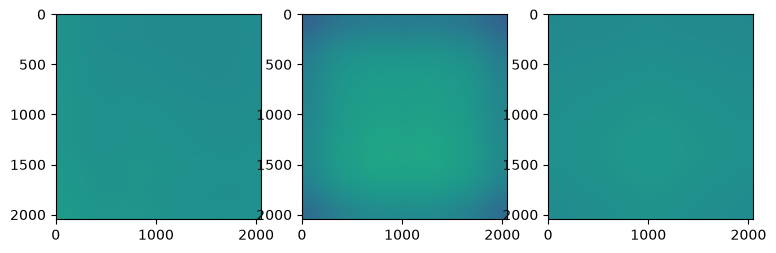

In [6]:
# step 2, run basicpy


basic_out = '/Volumes/Extreme_SSD/FtsZ_project/20260824_BsuFtsZ_TDL/20260910_basic.npy'
all_images = sorted(glob.glob('/Volumes/Extreme_SSD/FtsZ_project/20260824_BsuFtsZ_TDL/*.tif'))
seed = 42
rand_indices = np.random.permutation(np.arange(len(all_images)))[:100]
images = np.array([tifffile.imread(all_images[i]) for i in rand_indices])
n_channels = 3
basic_norm = []
clear_output()
for i in range(n_channels):
    ch_img = images[:,i]
    basic = mo.external.basicpy.BaSiC(get_darkfield=False, smoothness_flatfield=3)
    basic.fit(ch_img)
    basic_norm.append(basic)

fig,axes = plt.subplots(figsize=(n_channels*3,3),ncols=n_channels)
for i in range(n_channels):
    axes[i].imshow(basic_norm[i].flatfield,vmin=0.5,vmax=1.5,cmap='viridis')

# save BaSiC output
np.save(basic_out, np.array([basic_norm[i].flatfield for i in range(n_channels)]))